## Задача 1

In [8]:
!pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from rink import plot_rink

In [15]:
sns.set_theme(style="whitegrid")
events = pd.read_excel("/Users/danuhaha/Desktop/NHL-playoffs-2026.xlsx")
events = events.drop(columns=["Unnamed: 0"], errors="ignore")

In [16]:
events.shape

(29710, 38)

In [17]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


## Задача 2

In [18]:
games = events.groupby("Game ID").agg({
    "Date": "first",
    "Away Team": "first",
    "Home Team": "first",
    "Cumulated Away Score": "max",
    "Cumulated Home Score": "max",
    "Period": "max"
})
games = games.rename(columns={
    "Cumulated Away Score": "Away Score",
    "Cumulated Home Score": "Home Score"
})
games["Outcome"] = games["Period"].apply(
    lambda period: "Final" if period == 3 else "Final/OT" if period == 4 else f"Final/{period - 3}OT"
)
games = games.drop(columns="Period")

In [19]:
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

In [20]:
games.iloc[-5:,-4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


## Задача 3

In [21]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (f'{game["Home Team"]} - {game["Away Team"]} '
            f'({game["Home Score"]} - {game["Away Score"]}, '
            f'{game["Outcome"]}, {game["Date"]})')

In [22]:
gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [23]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

## Задача 4

In [24]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
games["Total Score"].describe()

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

## Задача 5

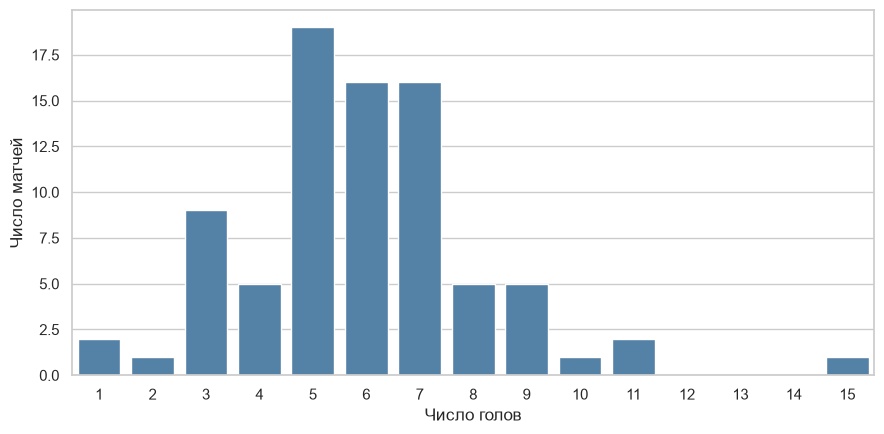

In [ ]:
plt.figure(figsize=(9, 4.5))
sns.countplot(data=games, x="Total Score", order=range(1, games["Total Score"].max() + 1), color="steelblue")
plt.xlabel("Число голов")
plt.ylabel("Число матчей")
plt.tight_layout()
plt.show()

In [28]:
print(games["Total Score"].median(), games["Total Score"]. mean())

6.0 5.926829268292683


В большинстве матчей забито 5–7 голов. Среднее значение - около 5,93, медиана - 6. Матчи с очень маленьким или очень большим числом голов встречаются редко

## Задача 6

In [29]:
least_goals = games.index[games["Total Score"] == games["Total Score"].min()]
most_goals = games.index[games["Total Score"] == games["Total Score"].max()]

In [30]:
[gameInfo(gameId) for gameId in least_goals]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [31]:
[gameInfo(gameId) for gameId in most_goals]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

## Задача 7

In [32]:
player_columns = [
    f"{side} Team's Player on the Ice #{number}"
    for side in ["Away", "Home"]
    for number in range(1, 7)
] + ["Away Team's Goalie", "Home Team's Goalie"]

players_in_games = events.melt(
    id_vars="Game ID", value_vars=player_columns, value_name="Player"
)[["Game ID", "Player"]].dropna().drop_duplicates()

player_counts = players_in_games.groupby("Game ID")["Player"].nunique()
most_players = player_counts[player_counts == player_counts.max()]
result_players = pd.DataFrame({
    "Game Info": [gameInfo(gameId) for gameId in most_players.index],
    "Player Count": most_players.values
}, index=most_players.index)
result_players.index.name = "Game ID"

In [33]:
result_players

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


## Задача 8. Расстояние каждого броска до створа ворот

In [36]:
shots = events[events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"])].copy()

home_shot = shots["Team Making the Play"] == shots["Home Team"]
home_defends_left = shots["Home Team's Defending Side"] == "left"

shots["Net X"] = np.where(home_shot == home_defends_left, 89, -89)
shots["Shot Length"] = np.sqrt(
    (shots["X Coordinate on the Ice Rink"] - shots["Net X"]) ** 2
    + np.maximum(np.abs(shots["Y Coordinate on the Ice Rink"]) - 3, 0) ** 2
)

In [35]:
shots[["Game ID", "Play Type", "Shot Length"]].round(3)

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


## Задача 9

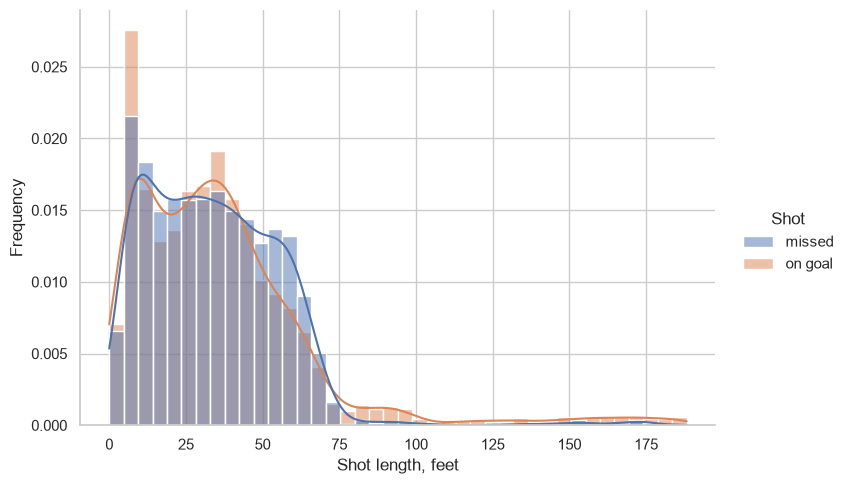

In [38]:
shots["Shot"] = np.where(shots["Play Type"] == "missed-shot", "missed", "on goal")
sns.displot(
    data=shots,
    x="Shot Length",
    hue="Shot",
    stat="density",
    common_norm=False,
    bins=40,
    kde=True,
    height=5,
    aspect=1.5
)
plt.xlabel("Shot length, feet")
plt.ylabel("Frequency")
plt.show()

Распределения точных и неточных бросков во многом похожи, основная масса бросков выполняется с относительно небольших и средних расстояний. Точных бросков с расстояния около 7 футов больше, видимо это оптимальное/удобное расстояние для гола. Длинный хвост точных бросков может объясняться бросками издалека по пустым воротам без вратаря 

## Задача 10

In [39]:
numshots = pd.crosstab(
    [shots["Game ID"], shots["Team Making the Play"]], shots["Shot"]
).reindex(columns=["missed", "on goal"], fill_value=0)

numshots["Share of Shots on Goal"] = numshots["on goal"] / (numshots["missed"] + numshots["on goal"])

In [43]:
numshots["Share of Shots on Goal"].round(3)

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Доля точных бросков различается между командами и матчами. Она показывает точность незаблокированных бросков, но не вероятность забить гол и сама по себе не определяет исход игры

## Задача 11

In [44]:
avgnumshots = numshots["Share of Shots on Goal"].groupby(level=1).mean()

In [45]:
display(avgnumshots.nlargest(5).round(3))

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [47]:

display(avgnumshots.nsmallest(5).round(3))

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Наибольшая средняя доля точных бросков у Edmonton Oilers, наименьшая — у Pittsburgh Penguins. Этот рейтинг описывает долю попаданий в ворота среди незаблокированных бросков.  Средние рассчитаны по матчам, поэтому каждый матч команды имеет одинаковый вес

## Задача 12

In [ ]:
team_games = pd.concat([games["Away Team"], games["Home Team"]]).value_counts()

shot_counts = events[events["Play Type"].isin(["shot-on-goal", "goal"])].groupby(
    ["Team Making the Play", "Play Type"]
).size().unstack(fill_value=0)

avgshots = pd.DataFrame(index=team_games.index)
avgshots["Shot"] = (shot_counts["shot-on-goal"] + shot_counts["goal"]) / team_games
avgshots["Goal"] = shot_counts["goal"] / team_games
avgshots = avgshots.sort_index()
avgshots.index.name = "Team Making the Play"

In [49]:
avgshots.round(3)

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## Задача 13

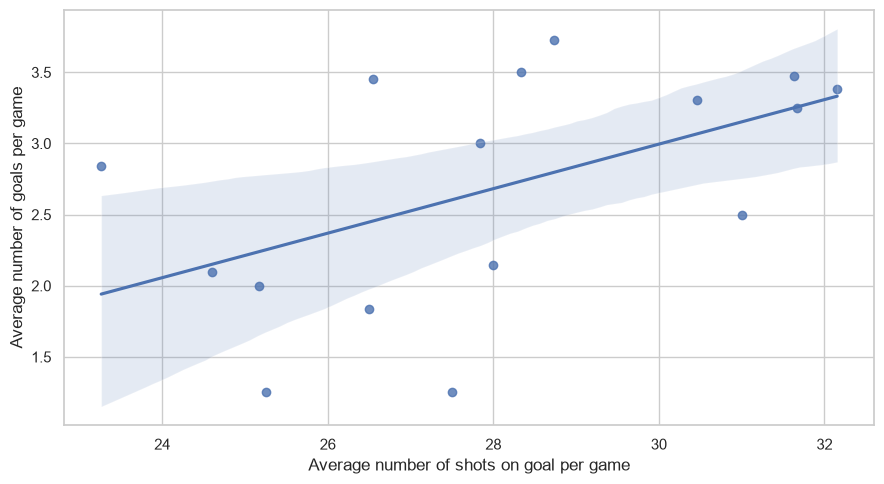

Коэффициент корреляции: 0.521


In [50]:
plt.figure(figsize=(9, 5))
sns.regplot(data=avgshots, x="Shot", y="Goal")
plt.xlabel("Average number of shots on goal per game")
plt.ylabel("Average number of goals per game")
plt.tight_layout()
plt.show()
print("Коэффициент корреляции:", round(avgshots["Shot"].corr(avgshots["Goal"]), 3))

Связь положительная и умеренная. Команды с большим числом бросков в среднем чаще забивают больше голов, однако заметный разброс показывает, что количество бросков — не единственный фактор результативности

## Задача 14

In [51]:
all_shot_types = ["shot-on-goal", "goal", "missed-shot", "blocked-shot"]
all_shots = events[events["Play Type"].isin(all_shot_types)].copy()
shots_per_game = all_shots.groupby("Game ID").size()
idxmax = shots_per_game.idxmax()

In [52]:
gameInfo(idxmax)

'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

In [53]:
print("Всего бросков:", shots_per_game.max())

Всего бросков: 208


## Задача 15

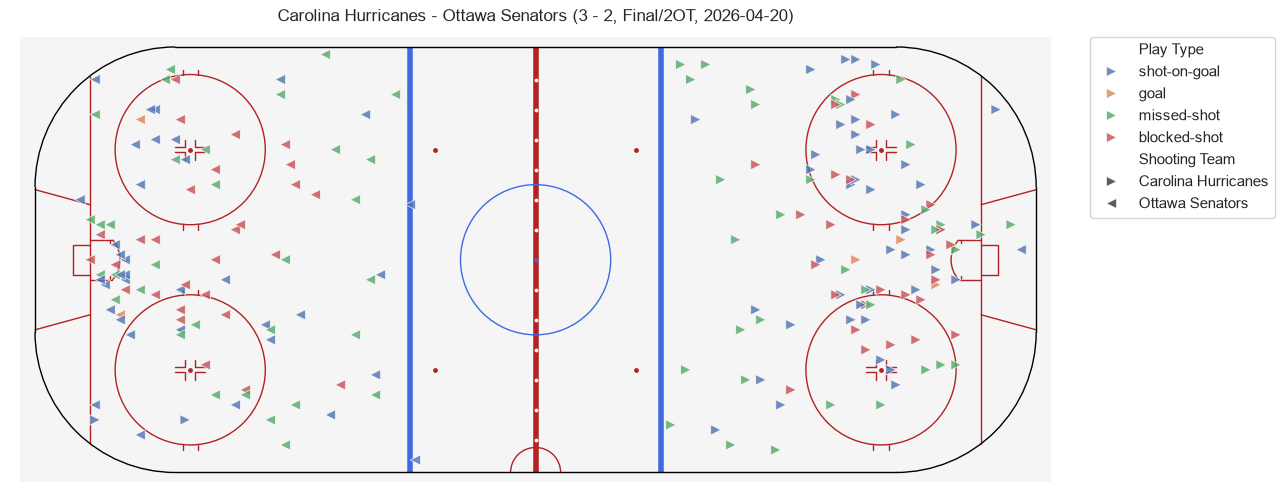

In [61]:
match_shots = all_shots[all_shots["Game ID"] == idxmax].copy()
match_shots["Shooting Team"] = match_shots["Team Making the Play"]
blocked = match_shots["Play Type"] == "blocked-shot"

match_shots["Plot X"] = np.where(
    match_shots["Period"] % 2 == 1,
    -match_shots["X Coordinate on the Ice Rink"],
    match_shots["X Coordinate on the Ice Rink"]
)
match_shots["Plot Y"] = np.where(
    match_shots["Period"] % 2 == 1,
    -match_shots["Y Coordinate on the Ice Rink"],
    match_shots["Y Coordinate on the Ice Rink"]
)

plt.figure(figsize=(13, 6))
plot_rink()
sns.scatterplot(
    data=match_shots,
    x="Plot X",
    y="Plot Y",
    hue="Play Type",
    hue_order=all_shot_types,
    style="Shooting Team",
    markers={
        "Carolina Hurricanes": ">",
        "Ottawa Senators": "<"
    },
    s=55,
    alpha=0.8
)
plt.gca().set_aspect("equal", adjustable="box")
plt.xlim(-105, 105)
plt.ylim(-46, 46)
plt.axis("off")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title(gameInfo(idxmax))
plt.tight_layout()
plt.show()

## Задача 16

In [64]:
goals = events[events["Play Type"] == "goal"].copy()
scorers = goals["Player in the Event #1"].value_counts()
display(scorers.head(10).rename("Goals"))

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: Goals, dtype: int64

## Задача 17

In [65]:
assists = pd.concat([
    goals["Player in the Event #2"],
    goals["Player in the Event #3"]
]).dropna().value_counts()
display(assists.head(10).rename("Assists"))

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: Assists, dtype: int64

## Задача 18

In [66]:
points = scorers.add(assists, fill_value=0).sort_values(ascending=False)
display(points.head(10).astype(int).rename("Points"))

Player in the Event #1
Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Nikolaj Ehlers     18
Shea Theodore      18
Pavel Dorofeyev    16
Lane Hutson        16
Logan Stankoven    16
Name: Points, dtype: int64

## Задача 19

In [67]:
games_played = players_in_games.groupby("Player")["Game ID"].nunique()
player_shots = events[events["Play Type"].isin(["shot-on-goal", "goal"])][
    "Player in the Event #1"
].value_counts()
shots_per_player_game = player_shots.div(games_played).dropna().sort_values(ascending=False)
display(shots_per_player_game.head(10).round(3).rename("Shots per Game"))

Player in the Event #1
Jason Robertson     5.000
Dylan Guenther      4.500
Nikita Kucherov     4.429
Matt Boldy          4.364
Quinton Byfield     4.250
Darren Raddysh      4.000
Joel Eriksson Ek    4.000
Alex Laferriere     3.750
David Pastrnak      3.667
Nathan MacKinnon    3.615
Name: Shots per Game, dtype: float64

## Задача 20

In [68]:
player_hits = events[events["Play Type"] == "hit"]["Player in the Event #1"].value_counts()
hits_per_player_game = player_hits.div(games_played).dropna().sort_values(ascending=False)
display(hits_per_player_game.head(10).round(3).rename("Hits per Game"))

Player in the Event #1
Lawson Crouse         6.333
Alex Turcotte         6.000
Alexander Petrovic    6.000
Yakov Trenin          5.667
Dylan Cozens          5.500
Vasily Podkolzin      5.333
Marcus Foligno        5.000
Ivan Barbashev        5.000
Carl Grundstrom       5.000
Owen Tippett          4.833
Name: Hits per Game, dtype: float64

## Задача 21

In [85]:
goalie_events = events.sort_values(["Game ID", "Play ID"]).copy()
ot_goals = (goalie_events["Play Type"] == "goal") & (goalie_events["Period"] > 3)

for side in ["Away", "Home"]:
    col = f"{side} Team's Goalie"
    goalie_events.loc[ot_goals, col] = goalie_events.groupby(
        ["Game ID", "Period"]
    )[col].ffill().loc[ot_goals]

goalie_games = pd.concat([
    goalie_events[["Game ID", "Away Team's Goalie"]].rename(columns={"Away Team's Goalie": "Goalie"}),
    goalie_events[["Game ID", "Home Team's Goalie"]].rename(columns={"Home Team's Goalie": "Goalie"})
]).dropna().drop_duplicates()

goalie_goals = goalie_events[goalie_events["Play Type"] == "goal"].copy()

goalie_goals["Defending Goalie"] = np.where(
    goalie_goals["Team Making the Play"] == goalie_goals["Home Team"],
    goalie_goals["Away Team's Goalie"],
    goalie_goals["Home Team's Goalie"]
)

conceded = goalie_goals.groupby(["Game ID", "Defending Goalie"]).size().rename("Goals Allowed")

goalie_results = goalie_games.join(conceded, on=["Game ID", "Goalie"])
goalie_results["Goals Allowed"] = goalie_results["Goals Allowed"].fillna(0).astype(int)

shutout_games = goalie_results[goalie_results["Goals Allowed"] == 0].sort_values(["Goalie", "Game ID"])

shutout_games["Goalie"].drop_duplicates().reset_index(drop=True).rename("Goalie")

0    Andrei Vasilevskiy
1         Brandon Bussi
2            Dan Vladar
3     Frederik Andersen
4      Joonas Korpisalo
5       Scott Wedgewood
Name: Goalie, dtype: str

Голы в пустые ворота не приписываются вратарю.

## Задача 22

Сколько раз команда проигрывала с разницей в две или более шайбы, но в итоге выигрывала матч?

In [84]:
comebacks = []

for game_id, game in games.iterrows():
    match = events[events["Game ID"] == game_id]

    if game["Home Score"] > game["Away Score"]:
        deficit = (match["Cumulated Away Score"] - match["Cumulated Home Score"]).max()
    else:
        deficit = (match["Cumulated Home Score"] - match["Cumulated Away Score"]).max()

    comebacks.append([game_id, max(0, deficit)])

comebacks = pd.DataFrame(comebacks, columns=["Game ID", "Maximum Deficit"])
comebacks = comebacks.set_index("Game ID")

big_comebacks = comebacks[comebacks["Maximum Deficit"] >= 2].copy()
big_comebacks["Game Info"] = [gameInfo(i) for i in big_comebacks.index]
big_comebacks = big_comebacks.sort_values("Maximum Deficit", ascending=False)

print(f"Камбэков с отставания в 2+ шайбы: {len(big_comebacks)} из {len(games)}")
print(f"Максимальное отставание, которое удалось отыграть: {comebacks['Maximum Deficit'].max()}")

display(big_comebacks[["Game Info", "Maximum Deficit"]])

Камбэков с отставания в 2+ шайбы: 9 из 82
Максимальное отставание, которое удалось отыграть: 3


,Game Info,Maximum Deficit
Game ID,,
2025030235,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi...",3
2025030323,Vegas Golden Knights - Colorado Avalanche (5 -...,3
2025030111,"Buffalo Sabres - Boston Bruins (4 - 3, Final, ...",2
2025030124,Montréal Canadiens - Tampa Bay Lightning (2 - ...,2
2025030184,"Anaheim Ducks - Edmonton Oilers (4 - 3, Final/...",2
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",2
2025030222,Carolina Hurricanes - Philadelphia Flyers (3 -...,2
2025030411,Carolina Hurricanes - Vegas Golden Knights (4 ...,2
2025030412,Carolina Hurricanes - Vegas Golden Knights (4 ...,2
